# L6 RG: results and evidence of unresolved DMRG convergence

**Completed scan: 456 field–disorder cases, each with two starts and $D_{\mathrm{MPS}}=32,64$.**
This notebook independently verifies the downloaded physical moments and reproduces every archived solver qualification decision.
It asks whether the tested solver settings give stable observables, especially $q_{\mathrm{EA}}$.

The evidence shows **sensitivity at the tested settings**, not a proof that the algorithm cannot converge.
Only two bond dimensions were tested; no $D\to\infty$ extrapolation is justified.

Parameters: $L=6$, $N=108$, $m=6$, $\chi=8$, $h=0.15$, $K_{ij}\sim U(0.5,1.5)$;
$\Gamma=0.100,0.125,\ldots,1.500$ and disorders 60000–60007.
Here $D_{\mathrm{MPS}}$ controls the effective-state solver; $m,\chi$ control RG retention and remain fixed.

**All diagnostic curves include unqualified cases**, visibly identified where relevant. They are evidence for assessing the solver,
not certified physical predictions. Individual-disorder curves have no error bars. Aggregate ribbons are **one standard error across the eight disorders only**;
starts and bond dimensions are never pooled as independent samples. This is a moment analysis, not a sampled $P(q)$ histogram.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'code/transformer_qmc/l6_d64_diagnostics.py').exists())
sys.path.insert(0, str(ROOT/'code'))
from transformer_qmc.l6_d64_diagnostics import analyze, DATA_NAME, GATE_LABELS
DATA = ROOT/'data/kagome'/DATA_NAME
FIG = ROOT/'figures/triangle_L6_m6_chi8_D64_convergence'
FIG.mkdir(parents=True, exist_ok=True)
records, comparisons, cases, summary = analyze(ROOT)
gammas = np.array(sorted(records.gamma.unique()))
ids = sorted(records.sample_id.unique())
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
colors = {0:'#0072B2', 1:'#D55E00'}
styles = {32:'--', 64:'-'}
labels = {'q_ea_finite':r'$q_{\rm EA}$', 'q2_raw':r'$\langle q^2\rangle$',
          'chi_sg_connected_equal_time':r'$\chi_{\rm SG,conn}$',
          'energy_per_spin':r'$E/N$'}
def finish(fig, name):
    fig.savefig(FIG/(name+'.png'), bbox_inches='tight')
    fig.savefig(FIG/(name+'.pdf'), bbox_inches='tight')
    plt.show()
    plt.close(fig)
def settings_legend():
    return [Line2D([0],[0],color=colors[s],ls=styles[D],label=f'start {s}, D={D}')
            for s in (0,1) for D in (32,64)]
display(Markdown(f"Verified **{len(records):,} physical-moment records**, "
                 f"**{len(cases)} cases**, and **{len(comparisons):,} matched comparisons**. "
                 f"All archived ladder/start/overall decisions reproduced. Archive SHA256: `{summary['archive_sha256']}`."))

Verified **1,824 physical-moment records**, **456 cases**, and **1,368 matched comparisons**. All archived ladder/start/overall decisions reproduced. Archive SHA256: `89d0de7415e5463a202d2a5208853fad155298715f27f0de2b4b8da35801c10d`.

## What the data actually establish

We distinguish failure of the complete solver checklist from instability of an individual observable.
Passing only the $q_{\mathrm{EA}}$ check does not override the original solver flag.

In [2]:
headline = pd.DataFrame([
    ('All solver checks pass', summary['solver_passed']),
    ('At least one solver check fails', summary['solver_failed']),
    ('D32 → D64 ladder fails in at least one start', summary['ladder_failed']),
    ('D64 starts fail to agree', summary['starts_failed']),
    ('q_EA checks fail', summary['gate_failure_cases']['q']),
    ('q_EA checks pass, but full solver checks fail', summary['full_fail_but_q_pass']),
    ('q_EA and <q²> checks pass', summary['q_and_q2_pass']),
    ('All three overlap-moment checks pass', summary['overlap_only_pass']),
], columns=['Assessment', 'Cases out of 456'])
display(headline)
display(Markdown('Counts overlap. In particular, **345 solver failures do not mean 345 unstable q_EA values**. '
                 'The q_EA checks use absolute differences ≤ 0.001 in both ladders and between the D64 starts.'))

,Assessment,Cases out of 456
0,All solver checks pass,111
1,At least one solver check fails,345
2,D32 → D64 ladder fails in at least one start,334
3,D64 starts fail to agree,22
4,q_EA checks fail,184
5,"q_EA checks pass, but full solver checks fail",161
6,q_EA and <q²> checks pass,271
7,All three overlap-moment checks pass,242


Counts overlap. In particular, **345 solver failures do not mean 345 unstable q_EA values**. The q_EA checks use absolute differences ≤ 0.001 in both ladders and between the D64 starts.

## Observable definitions and exact archived thresholds

$$q_{\mathrm{EA}}=\frac1N\sum_i\langle Z_i\rangle^2,\qquad
\langle q^2\rangle=\frac1{N^2}\sum_{ij}\langle Z_iZ_j\rangle^2,\qquad
\chi_{\mathrm{SG,raw}}=N\langle q^2\rangle.$$

$$\chi_{\mathrm{SG,conn}}=\frac1N\sum_{ij}
(\langle Z_iZ_j\rangle-\langle Z_i\rangle\langle Z_j\rangle)^2.$$

At nonzero $h$, $q_{\mathrm{EA}}$ includes polarization and is not by itself proof of glass order.
Overlap relative differences use $|a-b|/\max(|a|,|b|,10^{-10})$.
The archived spectrum test instead uses the maximum componentwise $|a-b|/\max(|a|,10^{-10})$,
with $a=D64$ for a ladder comparison and $a=\mathrm{start}\,0$ for a start comparison.

| Check | Within each start: D32 → D64 | Between starts at D64 |
|---|---:|---:|
| Energy difference per physical spin | $<10^{-7}$ | $<10^{-6}$ |
| Connected structure factors, maximum relative difference | $<0.005$ | $<0.01$ |
| $q_{\mathrm{EA}}$, absolute difference | $\le 0.001$ | $\le 0.001$ |
| $\langle q^2\rangle$, relative difference | $\le 0.005$ | $\le 0.01$ |
| Connected susceptibility, relative difference | $\le 0.005$ | $\le 0.01$ |
| Correlation-length ratio $R$, absolute difference | $<0.002$, both finite | $<0.002$, both finite |
| Last sweep energy change per spin | D64: $<10^{-8}$ | — |
| Canonical error | D64: $<10^{-8}$ | — |
| Truncation alarm | None at D32 or D64 | — |

These are the campaign's numerical tolerances, not statistical significance thresholds or bounds on error relative to the exact physical ground state.
The full source snapshots are saved alongside the data.

## Field curves: all eight disorders, all four solver settings

Each curve averages the same eight disorders. Ribbons are ± one disorder standard error at that setting.
All cases are shown regardless of qualification; agreement of disorder means can hide large individual changes.

## Individual-disorder evidence

Blue/orange distinguish starts; dashed/solid distinguish D32/D64. Crosses on the start-0 D64 curve mark cases that fail the full solver checklist.
They do not imply that this start is uniquely responsible. No error bars on individual disorders.

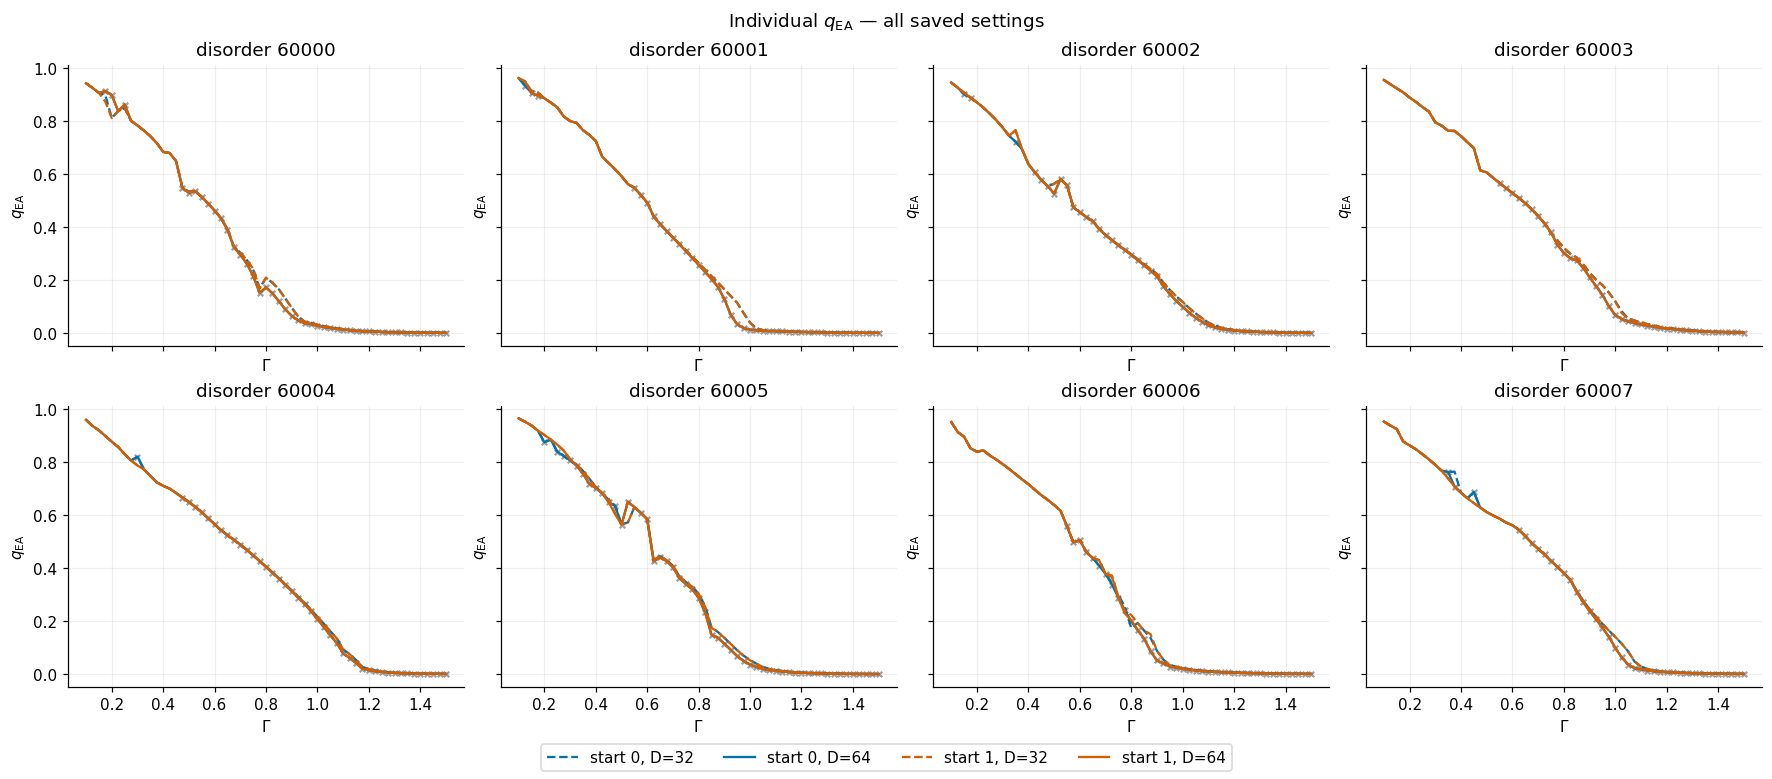

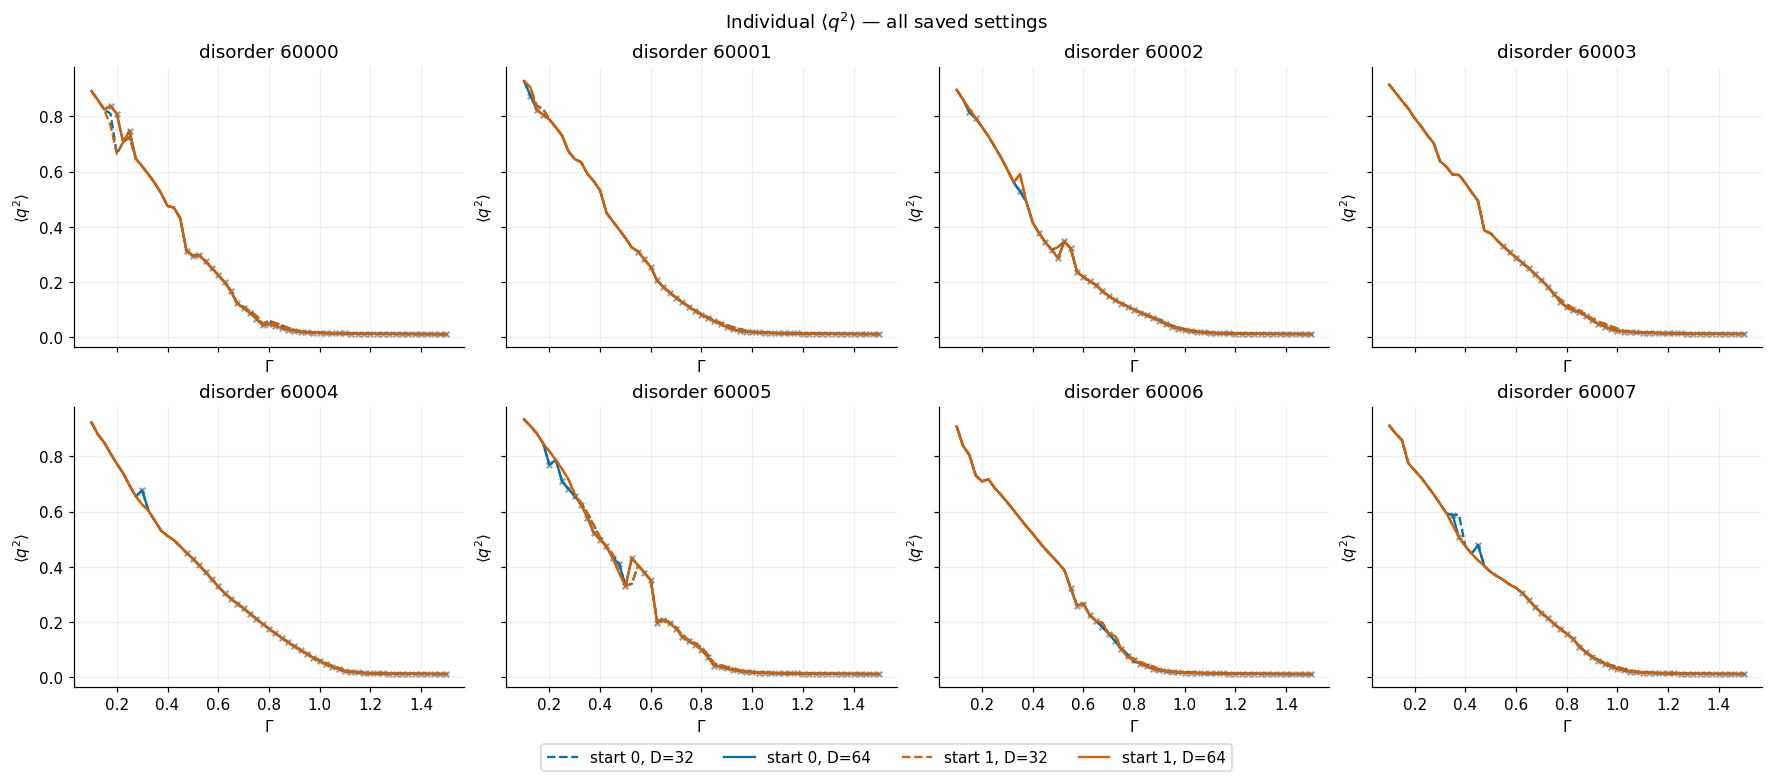

In [4]:
for key,filename in [('q_ea_finite','02_individual_qEA'),('q2_raw','03_individual_q2')]:
    fig, axes = plt.subplots(2,4,figsize=(16,7),layout='constrained',sharex=True,sharey=True)
    for ax,sid in zip(axes.flat,ids):
        for s in (0,1):
            for D in (32,64):
                a=records[(records.sample_id==sid)&(records.seed==s)&(records.D_MPS==D)].sort_values('gamma')
                ax.plot(a.gamma,a[key],color=colors[s],ls=styles[D],lw=1.5)
                if s==0 and D==64:
                    bad=a[~a.solver_passed]
                    ax.scatter(bad.gamma,bad[key],marker='x',s=13,color='#555555',alpha=.55)
        ax.set(title=f'disorder {sid}',xlabel=r'$\Gamma$',ylabel=labels[key])
        ax.grid(alpha=.2)
    fig.legend(handles=settings_legend(),loc='outside lower center',ncol=4)
    fig.suptitle('Individual '+labels[key]+' — all saved settings')
    finish(fig,filename)

## Where do the checks fail?

The left panels show the worst D32 → D64 change across the two starts at each field/disorder.
The right panels show the D64 difference between starts. Colors report **difference / allowed tolerance**:
values above one fail (energy uses a strict inequality). Very small values are clipped only for color display.

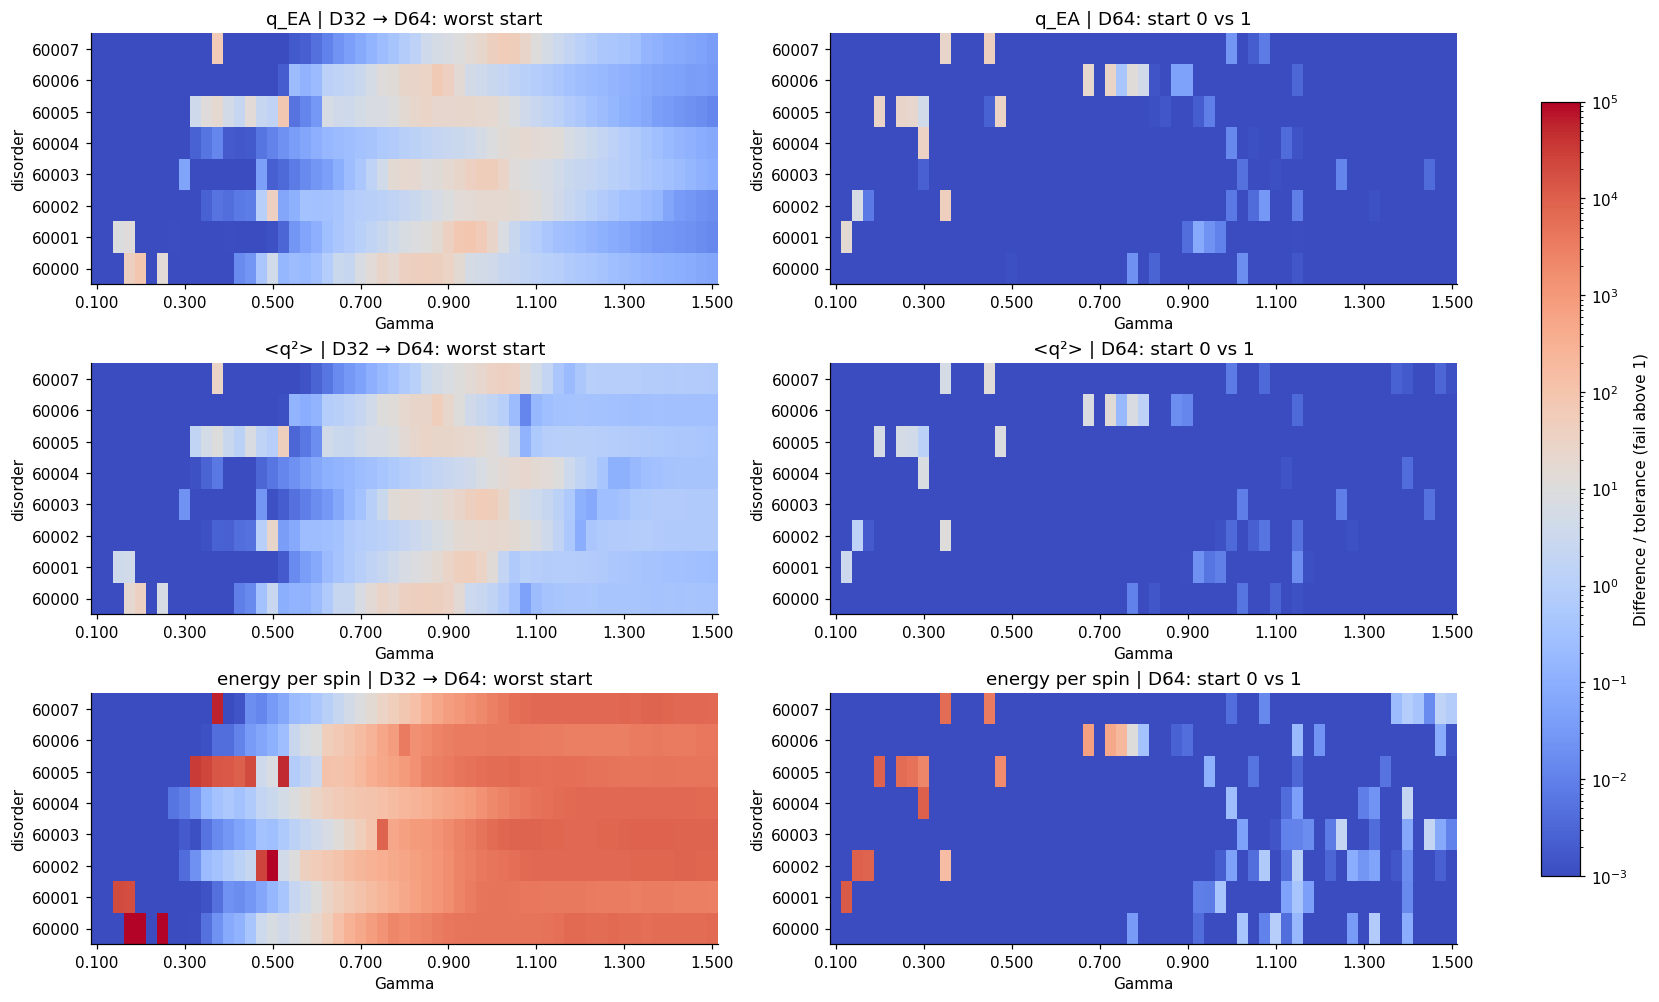

In [5]:
ladder=comparisons[comparisons.kind=='ladder']
starts=comparisons[comparisons.kind=='starts']
fig,axes=plt.subplots(3,2,figsize=(15,9),layout='constrained')
ticks=np.arange(0,len(gammas),8)
for row,(key,label) in enumerate([('q','q_EA'),('q2','<q²>'),('energy','energy per spin')]):
    for col,(frame,title) in enumerate([(ladder,'D32 → D64: worst start'),(starts,'D64: start 0 vs 1')]):
        values=frame.groupby(['sample_id','gamma'])[key+'_ratio'].max().unstack().reindex(index=ids,columns=gammas)
        im=axes[row,col].imshow(np.clip(values.to_numpy(),1e-3,1e5),aspect='auto',origin='lower',
                              cmap='coolwarm',norm=LogNorm(1e-3,1e5))
        axes[row,col].set(title=label+' | '+title,xticks=ticks,xticklabels=[f'{gammas[t]:.3f}' for t in ticks],
                          yticks=range(8),yticklabels=ids,xlabel='Gamma',ylabel='disorder')
fig.colorbar(im,ax=axes.ravel().tolist(),label='Difference / tolerance (fail above 1)',shrink=.85)
finish(fig,'04_tolerance_heatmaps')

## q_EA sensitivity versus the overall qualification flag

This classification separates the question “is q_EA stable under the tested changes?” from “did the complete solver pass?”.
A green field requires all eight disorders to pass the selected check; no failed disorder is silently removed.

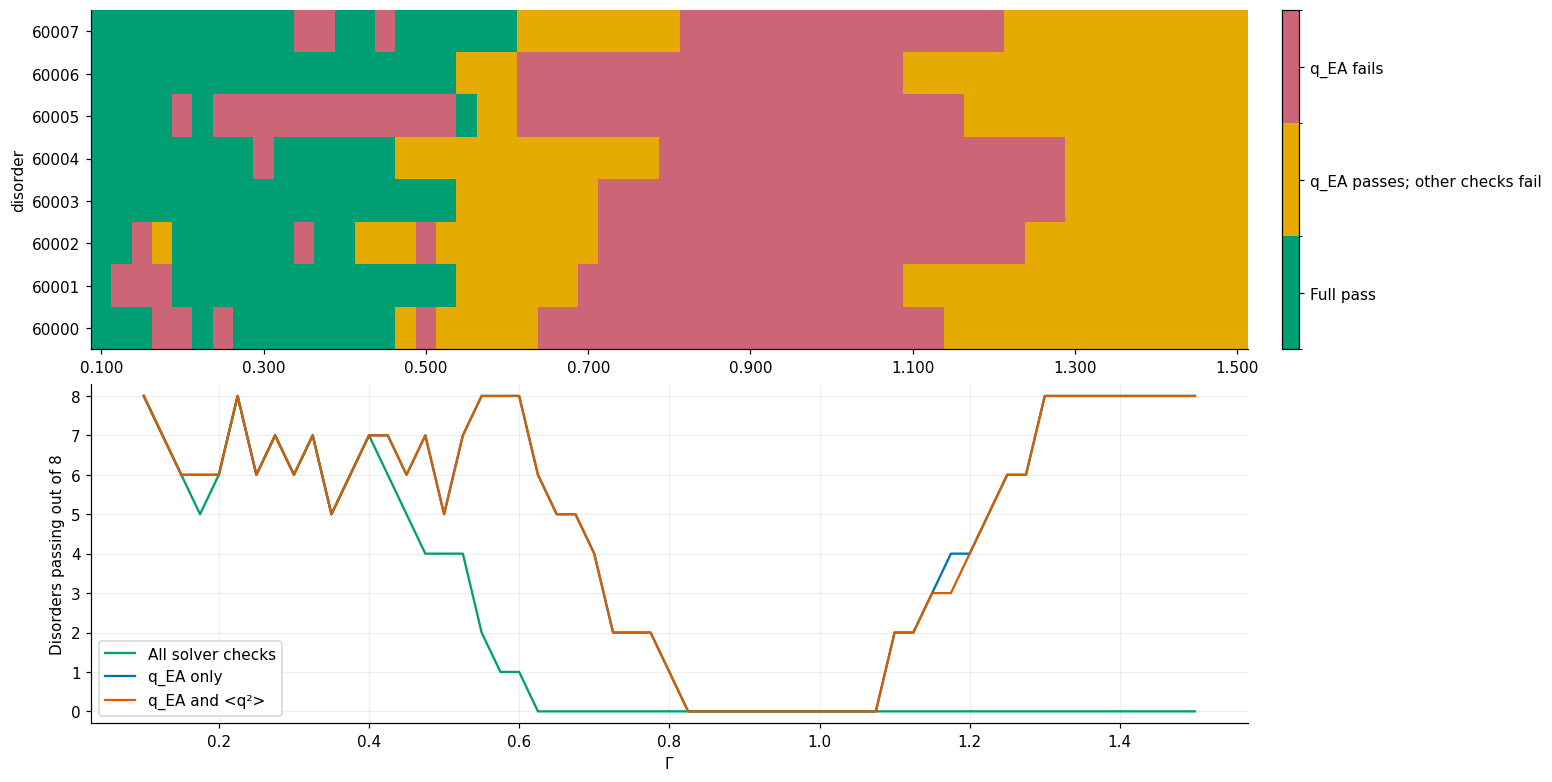

,Check,Ladder failure cases,Start disagreement cases
0,q_EA,174,15
1,<q²>,143,15
2,Connected susceptibility,197,16
3,All solver checks,334,22


In [6]:
classified=cases.copy()
classified['category']=np.where(classified.solver_passed,0,np.where(classified.q_pass,1,2))
grid=classified.pivot(index='sample_id',columns='gamma',values='category').reindex(index=ids,columns=gammas)
fig,axes=plt.subplots(2,1,figsize=(14,7),layout='constrained')
cmap=ListedColormap(['#009E73','#E6AB02','#CC6677'])
im=axes[0].imshow(grid,aspect='auto',origin='lower',cmap=cmap,norm=BoundaryNorm([-.5,.5,1.5,2.5],3))
axes[0].set(xticks=ticks,xticklabels=[f'{gammas[t]:.3f}' for t in ticks],yticks=range(8),yticklabels=ids,ylabel='disorder')
cb=fig.colorbar(im,ax=axes[0],ticks=[0,1,2],pad=.02)
cb.ax.set_yticklabels(['Full pass','q_EA passes; other checks fail','q_EA fails'])
for col,label,color in [('solver_passed','All solver checks','#009E73'),('q_pass','q_EA only','#0072B2'),
                        ('q_and_q2_pass','q_EA and <q²>','#D55E00')]:
    axes[1].plot(gammas,cases.groupby('gamma')[col].sum().reindex(gammas),label=label,color=color)
axes[1].set(xlabel=r'$\Gamma$',ylabel='Disorders passing out of 8',ylim=(-.3,8.3),yticks=range(9))
axes[1].legend(); axes[1].grid(alpha=.2)
finish(fig,'05_qEA_vs_overall')
display(pd.DataFrame({
    'Check':['q_EA','<q²>','Connected susceptibility','All solver checks'],
    'Ladder failure cases':[int((~cases[k]).sum()) for k in ['q_ladder_pass','q2_ladder_pass','connected_ladder_pass','ladder_pass']],
    'Start disagreement cases':[int((~cases[k]).sum()) for k in ['q_starts_pass','q2_starts_pass','connected_starts_pass','starts_pass']],
}))

## Concrete examples, including stable controls

Five cases illustrate different diagnoses. The first is a passing control; the next three exhibit large ladder drift,
start disagreement despite stable individual ladders, and drift accompanied by truncation alarms.
The last shows stable q_EA despite overall failure. These examples supplement the exhaustive plots above.
Two connected points are not a convergence fit. Energy is shown relative to the lowest saved energy for that case,
not relative to a known exact ground-state energy. Minimum vertical spans prevent roundoff-level differences
from appearing large: 0.004 for q_EA, 2% of the local magnitude for q², and 2×10⁻⁷ for energy per spin.

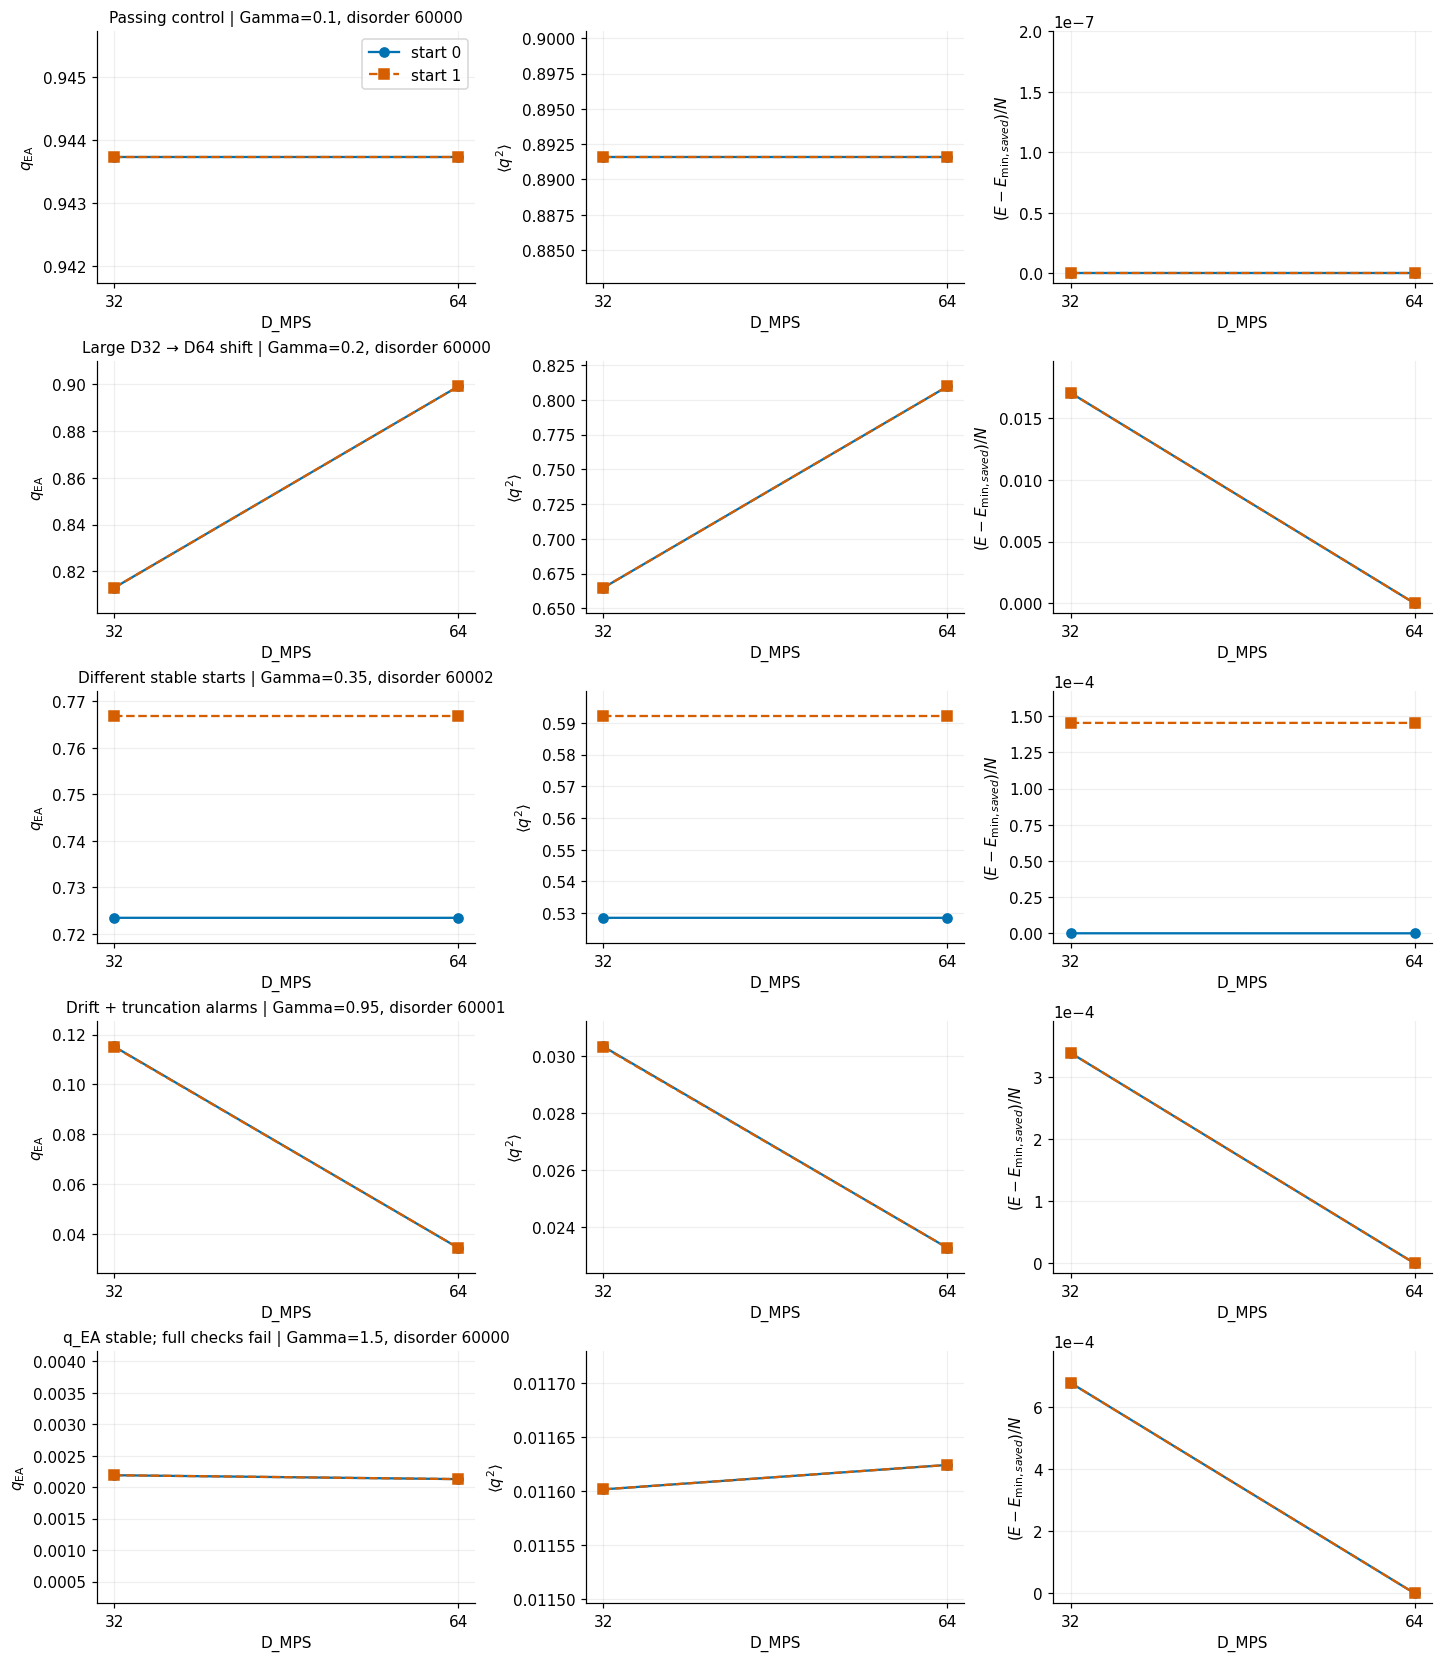

,gamma,sample_id,seed,D_MPS,q_ea_finite,q2_raw,energy_per_spin,max_bond,sweeps,truncation_failure
0,0.10,60000,0,32,0.943729,0.891581,-0.900832,32,19,None
1,0.10,60000,0,64,0.943729,0.891581,-0.900832,51,19,None
2,0.10,60000,1,32,0.943729,0.891581,-0.900832,32,19,None
3,0.10,60000,1,64,0.943729,0.891581,-0.900832,52,19,None
4,0.20,60000,0,32,0.812986,0.664784,-0.897539,32,19,None
5,0.20,60000,0,64,0.898929,0.809657,-0.914581,64,23,None
6,0.20,60000,1,32,0.812986,0.664784,-0.897539,32,19,None
7,0.20,60000,1,64,0.898929,0.809657,-0.914581,64,22,None
8,0.35,60002,0,32,0.723451,0.528491,-0.952667,32,32,None
9,0.35,60002,0,64,0.723448,0.528488,-0.952667,64,22,None


In [7]:
examples=[(.1,60000,'Passing control'),(.2,60000,'Large D32 → D64 shift'),
          (.35,60002,'Different stable starts'),(.95,60001,'Drift + truncation alarms'),
          (1.5,60000,'q_EA stable; full checks fail')]
fig,axes=plt.subplots(len(examples),3,figsize=(13,15),layout='constrained')
example_tables=[]
for row,(g,sid,title) in enumerate(examples):
    a=records[(records.gamma==g)&(records.sample_id==sid)].copy()
    a['energy_offset']=a.energy_per_spin-a.energy_per_spin.min()
    for col,key in enumerate(['q_ea_finite','q2_raw','energy_offset']):
        ax=axes[row,col]
        for seed in (0,1):
            b=a[a.seed==seed].sort_values('D_MPS')
            ax.plot(b.D_MPS,b[key],marker='o' if seed==0 else 's',color=colors[seed],
                    ls='-' if seed==0 else '--',label=f'start {seed}')
        ax.set(xticks=[32,64],xlabel='D_MPS',ylabel=labels.get(key,r'$(E-E_{\min,saved})/N$'))
        if key=='energy_offset':
            upper=max(float(a[key].max())*1.15, 2e-7)
            ax.set_ylim(-.04*upper,upper)
            ax.ticklabel_format(axis='y',style='sci',scilimits=(-3,3),useOffset=False)
        else:
            low,high=float(a[key].min()),float(a[key].max())
            minimum_span=.004 if key=='q_ea_finite' else max(.02*max(abs(low),abs(high)),1e-5)
            span=max((high-low)*1.25,minimum_span)
            center=(high+low)/2
            ax.set_ylim(center-span/2,center+span/2)
            ax.ticklabel_format(axis='y',style='plain',useOffset=False)
        ax.grid(alpha=.2)
        if col==0: ax.set_title(f'{title} | Gamma={g:g}, disorder {sid}',fontsize=10)
    example_tables.append(a[['gamma','sample_id','seed','D_MPS','q_ea_finite','q2_raw','energy_per_spin','max_bond','sweeps','truncation_failure']])
axes[0,0].legend()
finish(fig,'06_concrete_examples')
display(pd.concat(example_tables).reset_index(drop=True).round(9))

## Failure attribution and optimization diagnostics

Counts below overlap: a case can fail many checks. A truncation alarm is the saved TeNPy message
`Maximum truncation error (max_trunc_err) exceeded.` It is evidence of unresolved truncation in that run,
not a measured error bar on q_EA. The archived optimizer used up to 40 configured sweeps;
its recorded sweep index may be 41 because of the solver's indexing and termination convention.

,Gate,Any comparison fails,Ladder fails,Starts fail
0,Energy per spin,345,334,21.0
1,Connected structure factors,209,198,17.0
2,q_EA,184,174,15.0
3,<q²>,153,143,15.0
4,Connected susceptibility,208,197,16.0
5,Correlation-length ratio R,136,126,15.0
6,Last sweep energy,73,73,NaN
7,MPS canonical error,0,0,NaN
8,Current truncation alarm,228,228,NaN
9,Prior truncation alarm,250,250,NaN


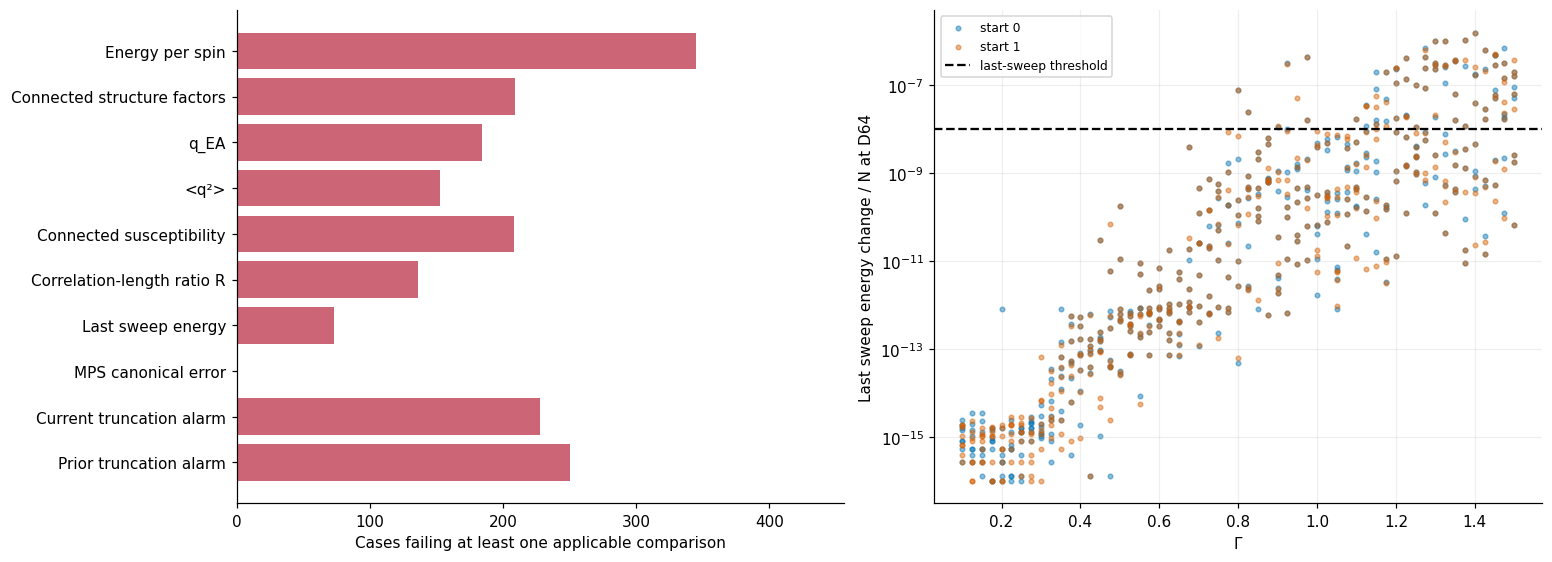

In [8]:
gate_table=pd.DataFrame([
    {'Gate':GATE_LABELS[k], 'Any comparison fails':int((~cases[k+'_pass']).sum()),
     'Ladder fails':int((~cases[k+'_ladder_pass']).sum()),
     'Starts fail':int((~cases[k+'_starts_pass']).sum()) if k in ['energy','spectrum','q','q2','connected','R'] else np.nan}
    for k in GATE_LABELS])
display(gate_table)
fig,axes=plt.subplots(1,2,figsize=(14,5),layout='constrained')
axes[0].barh(gate_table.Gate,gate_table['Any comparison fails'],color='#CC6677')
axes[0].invert_yaxis();axes[0].set(xlabel='Cases failing at least one applicable comparison',xlim=(0,456))
for s in (0,1):
    a=records[(records.seed==s)&(records.D_MPS==64)]
    axes[1].scatter(a.gamma,a.last_energy_change_per_spin.clip(lower=1e-16),s=9,alpha=.45,color=colors[s],label=f'start {s}')
axes[1].axhline(1e-8,color='black',ls='--',label='last-sweep threshold')
axes[1].set(yscale='log',xlabel=r'$\Gamma$',ylabel='Last sweep energy change / N at D64')
axes[1].legend(fontsize=8);axes[1].grid(alpha=.2)
finish(fig,'07_failure_attribution')

## Largest disagreements: exact saved numbers

These tables rank individual ladder comparisons and D64 start comparisons by absolute q_EA difference.
Both starts of the same case remain separate in the ladder table; they are not independent disorder realizations.

In [9]:
for kind in ['ladder','starts']:
    display(Markdown('**'+('D32 → D64' if kind=='ladder' else 'Between D64 starts')+'**'))
    top=comparisons[comparisons.kind==kind].nlargest(10,'q_delta')
    display(top[['gamma','sample_id','seed','q_delta','q_ratio','q2_delta','energy_delta','R_delta','failed_gates']].reset_index(drop=True))

**D32 → D64**

,gamma,sample_id,seed,q_delta,q_ratio,q2_delta,energy_delta,R_delta,failed_gates
0,0.200,60000,1,0.085943,85.943125,0.178931,0.017042,0.071969,"energy, spectrum, q, q2, connected, R"
1,0.200,60000,0,0.085943,85.943125,0.178931,0.017042,0.071969,"energy, spectrum, q, q2, connected, R"
2,0.950,60001,0,0.080799,80.798617,0.233335,0.000338,0.070861,"energy, spectrum, q, q2, connected, R, truncat..."
3,0.950,60001,1,0.080654,80.654344,0.232849,0.000338,0.070780,"energy, spectrum, q, q2, connected, R, truncat..."
4,0.525,60005,1,0.077979,77.978798,0.214106,0.005027,0.041249,"energy, spectrum, q, q2, connected, R"
5,0.525,60005,0,0.077967,77.966546,0.214077,0.005027,0.041237,"energy, spectrum, q, q2, connected, R"
6,0.925,60001,0,0.071409,71.408954,0.220607,0.000242,0.060773,"energy, spectrum, q, q2, connected, R, last_en..."
7,0.925,60001,1,0.071337,71.337495,0.220627,0.000244,0.060680,"energy, spectrum, q, q2, connected, R, truncat..."
8,0.875,60006,1,0.064244,64.244285,0.230938,0.000244,0.041470,"energy, spectrum, q, q2, connected, R, truncat..."
9,0.975,60001,0,0.056634,56.634260,0.153237,0.000422,0.052473,"energy, spectrum, q, q2, connected, R, last_en..."


**Between D64 starts**

,gamma,sample_id,seed,q_delta,q_ratio,q2_delta,energy_delta,R_delta,failed_gates
0,0.350,60002,-1,0.043272,43.272243,0.107335,0.000145,0.025270,"energy, spectrum, q, q2, connected, R"
1,0.450,60007,-1,0.041591,41.590951,0.115070,0.003581,0.022599,"energy, spectrum, q, q2, connected, R"
2,0.300,60004,-1,0.032683,32.683037,0.076207,0.009423,0.067294,"energy, spectrum, q, q2, connected, R"
3,0.475,60005,-1,0.031430,31.429605,0.085779,0.001792,0.040451,"energy, spectrum, q, q2, connected, R"
4,0.725,60006,-1,0.028069,28.069223,0.127967,0.000467,0.026860,"energy, spectrum, q, q2, connected, R"
5,0.200,60005,-1,0.027603,27.602698,0.059620,0.008740,0.005995,"energy, spectrum, q, q2, connected, R"
6,0.250,60005,-1,0.026243,26.242634,0.059121,0.006357,0.007029,"energy, spectrum, q, q2, connected, R"
7,0.350,60007,-1,0.023776,23.775714,0.059708,0.006208,0.017125,"energy, spectrum, q, q2, connected, R"
8,0.275,60005,-1,0.020627,20.626759,0.047949,0.004987,0.004048,"energy, spectrum, q, q2, connected, R"
9,0.675,60006,-1,0.019821,19.820592,0.079991,0.000726,0.015766,"energy, spectrum, q, q2, connected, R"


## Interpretation and next diagnostic

**The present data do not support a blanket statement that all 345 excluded q_EA values are unconverged.**
Of 456 cases, 272 pass the tested q_EA tolerance and 184 fail it; 161 pass q_EA while failing the full checklist.
There are 174 cases with q_EA ladder drift above 0.001 and 15 with D64 start disagreement above 0.001 (five overlap).
Both q_EA and $\langle q^2\rangle$ pass their tested tolerances in 271 cases.

The clearest evidence is local, not just a red qualification flag:

- At $\Gamma=0.200$, disorder 60000, q_EA changes from approximately **0.812986 to 0.898929** when going from D32 to D64, in both starts.
- At $\Gamma=0.350$, disorder 60002, each start is nearly unchanged along the ladder, but their D64 q_EA values are approximately **0.723448 and 0.766720**. Agreement along one ladder is insufficient.
- At $\Gamma=0.950$, disorder 60001, start 0 changes from approximately **0.115240 to 0.034442**, with truncation alarms at both dimensions.
- At $\Gamma=1.500$, disorder 60000, q_EA changes by only about **0.000062**, despite overall failure. This is a counterexample to equating every solver failure with an unstable primary observable.

**Larger D is a justified next diagnostic, not a guaranteed cure.** Continue matched saved states at D128 (and D256 if needed), retain both starts,
and check additional optimization where starts disagree or sweep convergence is unresolved. A D32→D64 change can reflect both increased state capacity
and the additional optimization performed at D64; the current experiment does not isolate those causes.
Agreement at two dimensions does not prove a plateau, and two starts can share a metastable state.

The q_EA discrepancies are not explained solely by the correlation-length check: they are direct differences in physical moments,
recomputed from saved $\langle Z_i\rangle$ arrays. After solver stability, assess $m$ and $\chi$ retention independently before finite-size scaling.
This notebook performs analysis only and does not launch a larger-D campaign.

## Local evidence and reproducibility

The notebook runs without SSH or TeNPy. Requirements: Python, NumPy, pandas, matplotlib, nbformat and IPython.
Run all cells from this notebook's directory or the repository root.

- `data/kagome/triangle_L6_m6_chi8_D64_diagnostics_20261106/raw/`: downloaded case/stage JSON, all 1,824 physical-moment NPZ files, audits, campaign metadata and solver source snapshots.
- `records.csv`, `comparisons.csv`, `cases.csv`: complete plotted values and reconstructed checks, including all failed cases.
- `summary.json`, `verified_inventory.json`: validation results and SHA256 inventory of case results and physical-moment files.
- `evidence.tar.gz`: original downloaded evidence bundle, retained for provenance.
- `figures/triangle_L6_m6_chi8_D64_convergence/`: standalone PNG/PDF exports of every figure.

Original MPS/model pickle checkpoints remain in the remote campaign directory. Local analysis recomputes moments from NPZ files,
checks their hashes against case manifests, verifies matching disorder couplings across all fields/settings,
and reproduces the archived ladder, start-agreement and overall pass/fail decisions for every case.

In [10]:
display(Markdown('**Remote source:** `'+summary['remote_root']+'`'))
display(pd.DataFrame(sorted(summary['source_sha256'].items()),columns=['Archived source','SHA256']))
assert len(records)==1824 and len(comparisons)==1368 and len(cases)==456
assert int(cases.solver_passed.sum())==111
assert int((~cases.q_pass).sum())==184
assert int((~cases.q_ladder_pass & ~cases.q_starts_pass).sum())==5
print('All completeness, moment-reconstruction, source-hash and qualification checks passed.')

**Remote source:** `/root/autodl-tmp/triangle-L6-m6-c8-D64-dense-20261105-v1`

,Archived source,SHA256
0,triangle_correlation_dmrg.py,4098e68bf9af5c8753536721057625df2afe3f538c5e69...
1,triangle_correlation_observables.py,c85a182feaa279fb53cb02bfbc860500505ab761b41348...
2,triangle_effective_mps.py,a5d092b8525fa6c5215715711a432195903cd5161b2a04...
3,triangle_effective_rg.py,907c95ac92296cc21a511bbafbf27a2512c6e5e0359faf...
4,triangle_l6_chi8_dense.py,34f641c791ddf5d083945c6b7d3bc3eccf1d510561dd34...
5,triangle_overlap_report.py,3e8d2518008dbd0b93d6818f78f61315a2534ef39a3cbc...


All completeness, moment-reconstruction, source-hash and qualification checks passed.
